# Brent's method

Brent's method combines bracketing with fast interpolation. The two cells below are self-contained versions of the figure scripts:

1. **Minimization** (`brent_min`): golden-section steps mixed with successive parabolic interpolation.
2. **Root finding** (`brent_root`): bisection mixed with secant and inverse quadratic interpolation, for a monotonic function.

Each cell prints the iteration trace and saves a PNG and PDF in this folder.

## 1. Minimization

it  0  x=2.800000  f=-1.706721  start      bracket=[0.0000, 3.0000]
it  1  x=1.730495  f=-5.288712  golden     bracket=[0.0000, 2.8000]
it  2  x=1.069505  f=-0.415155  golden     bracket=[1.0695, 2.8000]
it  3  x=1.994980  f=-6.214845  parabolic  bracket=[1.7305, 2.8000]
it  4  x=2.068471  f=-6.306282  parabolic  bracket=[1.9950, 2.8000]
it  5  x=2.124865  f=-6.322909  parabolic  bracket=[2.0685, 2.8000]
it  6  x=2.116836  f=-6.323462  parabolic  bracket=[2.0685, 2.1249]
it  7  x=2.114719  f=-6.323444  parabolic  bracket=[2.1147, 2.1249]
it  8  x=2.118953  f=-6.323411  parabolic  bracket=[2.1147, 2.1190]
Brent minimum: 2.1189531098232086 f = -6.3234114151730125


saved brent_method.png / brent_method.pdf


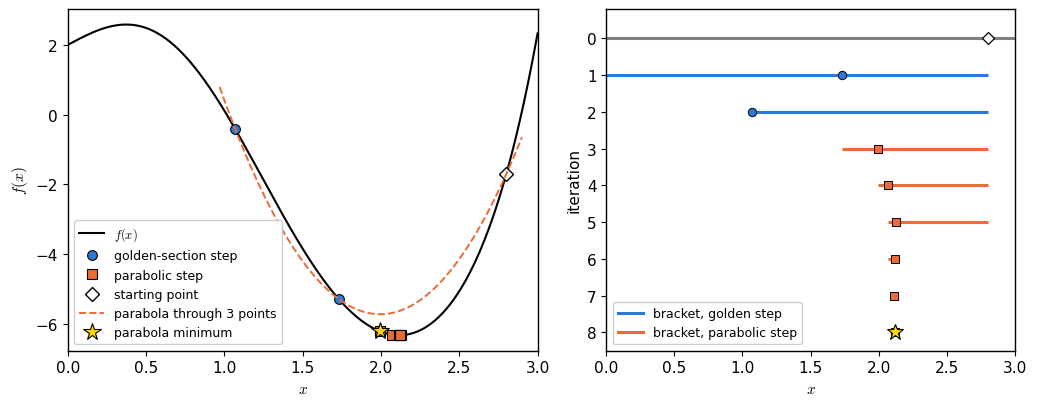

In [1]:
"""Visualize Brent's method for 1-D minimization.

Brent's method combines golden-section search (always shrinks the bracket,
guaranteed but slow) with successive parabolic interpolation (fast near a
smooth minimum). This script runs Brent's algorithm on a test function,
records every evaluation and whether it came from a parabolic or a golden
step, and plots:
  (a) the function, the evaluation points, and one parabolic fit;
  (b) the shrinking bracket [a, b] at each iteration.
"""
from math import sqrt, floor, ceil, log10
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0,
                     "font.family": "DejaVu Sans", "mathtext.fontset": "cm"})

BLUE = "#2b7bd6"    # golden-section steps (matches earlier figure)
ORANGE = "#ec6b35"  # parabolic steps (matches earlier figure)


def f(x):
    # non-quadratic function on [0, 3]: parabolic fits are only approximate
    return x**4 - 3.0 * x**3 + 2.0 + 0.8 * np.sin(3.0 * x)


def brent_min(func, a, b, x0, tol=1e-8, maxiter=100):
    """Brent (1973) minimization. Returns the trace of evaluations."""
    c = (3.0 - sqrt(5.0)) / 2.0  # golden-section fraction
    eps = np.finfo(float).eps
    x = w = v = x0
    fx = fw = fv = func(x)
    d = e = 0.0
    trace = [dict(it=0, x=x, fx=fx, kind="start", a=a, b=b, parab=None)]
    for it in range(1, maxiter + 1):
        xm = 0.5 * (a + b)
        tol1 = tol * abs(x) + eps
        tol2 = 2.0 * tol1
        if abs(x - xm) <= tol2 - 0.5 * (b - a):
            break
        parab = None
        kind = "golden"
        if abs(e) > tol1:
            # try a parabola through (v, fv), (w, fw), (x, fx)
            r = (x - w) * (fx - fv)
            q = (x - v) * (fx - fw)
            p = (x - v) * q - (x - w) * r
            q = 2.0 * (q - r)
            if q > 0.0:
                p = -p
            q = abs(q)
            etemp = e
            e = d
            if (abs(p) >= abs(0.5 * q * etemp) or p <= q * (a - x)
                    or p >= q * (b - x)):
                e = (a - x) if x >= xm else (b - x)   # golden step
                d = c * e
            else:
                d = p / q                              # parabolic step
                u_try = x + d
                parab = (v, w, x, fv, fw, fx)
                kind = "parabolic"
                if (u_try - a) < tol2 or (b - u_try) < tol2:
                    d = np.sign(xm - x) * tol1
        else:
            e = (a - x) if x >= xm else (b - x)
            d = c * e
        u = x + d if abs(d) >= tol1 else x + np.sign(d) * tol1
        fu = func(u)
        if fu <= fx:
            if u >= x:
                a = x
            else:
                b = x
            v, fv = w, fw
            w, fw = x, fx
            x, fx = u, fu
        else:
            if u < x:
                a = u
            else:
                b = u
            if fu <= fw or w == x:
                v, fv = w, fw
                w, fw = u, fu
            elif fu <= fv or v == x or v == w:
                v, fv = u, fu
        trace.append(dict(it=it, x=u, fx=fu, kind=kind, a=a, b=b, parab=parab))
    return trace


def save_fig(fig, name, **kwargs):
    fig.savefig(f"{name}.png", dpi=600, bbox_inches="tight", **kwargs)
    fig.savefig(f"{name}.pdf", bbox_inches="tight", **kwargs)


def main():
    A, B, X0 = 0.0, 3.0, 2.8
    trace = brent_min(f, A, B, X0, tol=1e-3)
    xs = np.linspace(A, B, 800)

    # ---- console summary so the numbers can be checked --------------------
    for t in trace:
        print(f"it {t['it']:2d}  x={t['x']:.6f}  f={t['fx']:.6f}  "
              f"{t['kind']:9s}  bracket=[{t['a']:.4f}, {t['b']:.4f}]")
    print("Brent minimum:", trace[-1]["x"], "f =", trace[-1]["fx"])

    # pick the first parabolic step to illustrate the fit
    par_steps = [t for t in trace if t["kind"] == "parabolic"]
    fit_step = par_steps[0] if par_steps else None

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2),
                                   gridspec_kw={"width_ratios": [1.15, 1]})

    # ---------------- panel (a): function, evaluations, parabola fit -------
    ax1.plot(xs, f(xs), color="k", lw=1.5, label=r"$f(x)$")
    gold = [t for t in trace[1:] if t["kind"] == "golden"]
    para = [t for t in trace[1:] if t["kind"] == "parabolic"]
    ax1.plot([t["x"] for t in gold], [t["fx"] for t in gold], ls="none",
             marker="o", ms=7, mfc=BLUE, mec="k", mew=0.8,
             label="golden-section step")
    ax1.plot([t["x"] for t in para], [t["fx"] for t in para], ls="none",
             marker="s", ms=7, mfc=ORANGE, mec="k", mew=0.8,
             label="parabolic step")
    ax1.plot(trace[0]["x"], trace[0]["fx"], ls="none", marker="D", ms=7,
             mfc="w", mec="k", mew=1.0, label="starting point")

    if fit_step is not None:
        v, w, x, fv, fw, fx = fit_step["parab"]
        # quadratic through the three points (v,fv), (w,fw), (x,fx)
        M = np.array([[v * v, v, 1.0], [w * w, w, 1.0], [x * x, x, 1.0]])
        coef = np.linalg.solve(M, np.array([fv, fw, fx]))
        xp = np.linspace(min(v, w, x) - 0.1, max(v, w, x) + 0.1, 200)
        ax1.plot(xp, coef[0] * xp**2 + coef[1] * xp + coef[2], ls="--",
                 color=ORANGE, lw=1.4, label="parabola through 3 points")
        ax1.plot(fit_step["x"], fit_step["fx"], marker="*", ms=13, ls="none",
                 mfc="gold", mec="k", mew=0.8, zorder=6,
                 label="parabola minimum")

    ax1.set_xlabel(r"$x$")
    ax1.set_ylabel(r"$f(x)$")
    ax1.set_xlim(A, B)
    ax1.legend(loc="lower left", frameon=True, fontsize=9, framealpha=0.95)

    # ---------------- panel (b): bracket shrinking ------------------------
    rows = [t for t in trace if t["it"] >= 0]
    for t in rows:
        if t["it"] == 0:
            continue
        col = ORANGE if t["kind"] == "parabolic" else BLUE
        ax2.plot([t["a"], t["b"]], [t["it"], t["it"]], color=col, lw=2.2,
                 solid_capstyle="butt")
        ax2.plot(t["x"], t["it"], ls="none",
                 marker="s" if t["kind"] == "parabolic" else "o",
                 ms=6, mfc=col, mec="k", mew=0.7)
    ax2.plot([trace[0]["a"], trace[0]["b"]], [0, 0], color="0.5", lw=2.2,
             solid_capstyle="butt")
    ax2.plot(trace[0]["x"], 0, ls="none", marker="D", ms=6, mfc="w",
             mec="k", mew=0.9)
    ax2.plot(trace[-1]["x"], trace[-1]["it"], ls="none", marker="*", ms=12,
             mfc="gold", mec="k", mew=0.8)
    ax2.set_xlabel(r"$x$")
    ax2.set_ylabel("iteration")
    ax2.set_xlim(A, B)
    ax2.set_ylim(len(trace) - 0.5, -0.8)  # iteration 0 at top
    ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

    # legend for panel (b): proxy handles for line color + marker
    from matplotlib.lines import Line2D
    handles = [
        Line2D([0], [0], color=BLUE, lw=2.2, label="bracket, golden step"),
        Line2D([0], [0], color=ORANGE, lw=2.2, label="bracket, parabolic step"),
    ]
    ax2.legend(handles=handles, loc="lower left", frameon=True, fontsize=9,
               framealpha=0.95)

    fig.tight_layout()
    save_fig(fig, "brent_method")
    print("saved brent_method.png / brent_method.pdf")


main()


## 2. Finding a zero of a monotonic function

it  0  x=3.0000000000  f=+2.800e+01  start      bracket=[0.000000, 3.000000]
it  1  x=0.4545454545  f=-3.997e+00  secant     bracket=[0.454545, 3.000000]
it  2  x=1.7272727273  f=+3.608e+00  bisection  bracket=[1.727273, 3.000000]
it  3  x=1.1234754181  f=-1.335e+00  secant     bracket=[0.454545, 1.123475]
it  4  x=1.2865546426  f=-2.974e-01  secant     bracket=[1.286555, 1.727273]
it  5  x=1.3297294607  f=+1.066e-02  IQI        bracket=[1.329729, 1.727273]
it  6  x=1.3282351680  f=-2.457e-04  secant     bracket=[1.286555, 1.328235]
it  7  x=1.3282688288  f=-1.960e-07  secant     bracket=[1.328269, 1.329729]
it  8  x=1.3282688557  f=+5.329e-15  IQI        bracket=[1.328269, 1.329729]
it  9  x=1.3282688556  f=-3.646e-10  secant     bracket=[1.328269, 1.328269]
Brent root: 1.3282688556186084


saved brent_root_method.png / brent_root_method.pdf


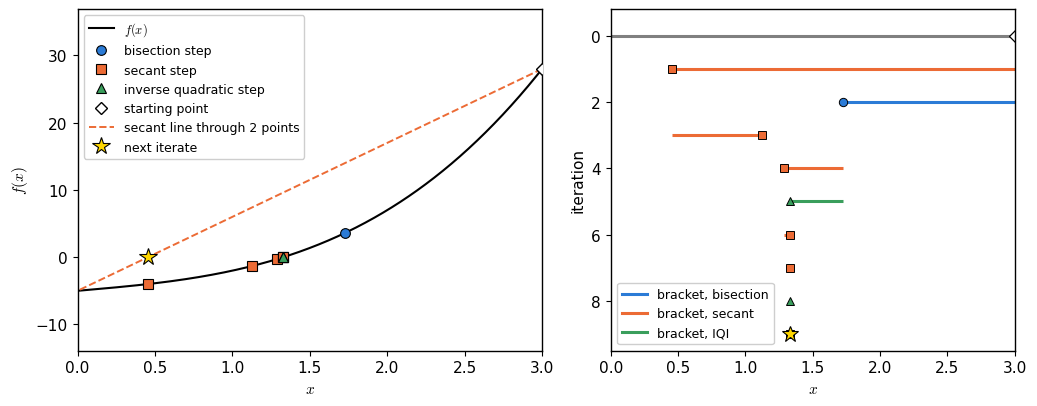

In [2]:
"""Visualize Brent's method for finding a zero of a monotonic function.

Brent's root finder keeps a sign-changing bracket [a, b]. Each step uses
inverse quadratic interpolation (IQI) or secant interpolation when those
look safe, and falls back to bisection otherwise. This script runs the
algorithm (Brent 1973, zeroin) on a monotonic test function, records each
iterate and its step type, and plots:
  (a) the function, the iterates, and one interpolation step;
  (b) the shrinking bracket [a, b] at each iteration.
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0,
                     "font.family": "DejaVu Sans", "mathtext.fontset": "cm"})

BLUE = "#2b7bd6"    # bisection (matches earlier figure)
ORANGE = "#ec6b35"  # secant / IQI interpolation (matches earlier figure)
GREEN = "#3a9e5c"   # inverse quadratic interpolation


def f(x):
    # strictly increasing on the whole real line, one zero near x = 1.3283
    return x**3 + 2.0 * x - 5.0


def brent_root(func, a, b, tol=1e-10, maxiter=100):
    """Brent (1973) zeroin. Returns the trace of iterates."""
    fa, fb = func(a), func(b)
    if fa * fb > 0:
        raise ValueError("root not bracketed")
    c, fc = a, fa
    d = e = b - a
    trace = [dict(it=0, x=b, fx=fb, kind="start", a=a, b=b, pts=None)]
    for it in range(1, maxiter + 1):
        if fb * fc > 0:            # keep b and c on opposite sides
            c, fc = a, fa
            d = e = b - a
        if abs(fc) < abs(fb):      # b is always the best estimate
            a, b, c = b, c, b
            fa, fb, fc = fb, fc, fb
        tol1 = 2.0 * np.finfo(float).eps * abs(b) + 0.5 * tol
        xm = 0.5 * (c - b)
        if abs(xm) <= tol1 or fb == 0.0:
            break
        kind = "bisection"
        pts = None
        if abs(e) >= tol1 and abs(fa) > abs(fb):
            # try interpolation: secant if a == c, otherwise inverse quadratic
            s = fb / fa
            if a == c:
                p = 2.0 * xm * s
                q = 1.0 - s
                kind = "secant"
                pts = (a, b)
            else:
                q = fa / fc
                r = fb / fc
                p = s * (2.0 * xm * q * (q - r) - (b - a) * (r - 1.0))
                q = (q - 1.0) * (r - 1.0) * (s - 1.0)
                kind = "IQI"
                pts = (a, b, c)
            if p > 0.0:
                q = -q
            else:
                p = -p
            if 2.0 * p < min(3.0 * xm * q - abs(tol1 * q), abs(e * q)):
                e = d
                d = p / q          # accept interpolation step
            else:
                kind = "bisection"
                pts = None
                d = xm
                e = d
        else:
            d = xm
            e = d
        a, fa = b, fb
        b = b + d if abs(d) > tol1 else b + np.sign(xm) * tol1
        fb = func(b)
        trace.append(dict(it=it, x=b, fx=fb, kind=kind, a=min(b, c),
                          b=max(b, c), pts=pts))
    return trace


def save_fig(fig, name, **kwargs):
    fig.savefig(f"{name}.png", dpi=600, bbox_inches="tight", **kwargs)
    fig.savefig(f"{name}.pdf", bbox_inches="tight", **kwargs)


def main():
    A, B = 0.0, 3.0
    trace = brent_root(f, A, B)
    xs = np.linspace(A, B, 600)

    for t in trace:
        print(f"it {t['it']:2d}  x={t['x']:.10f}  f={t['fx']:+.3e}  "
              f"{t['kind']:9s}  bracket=[{t['a']:.6f}, {t['b']:.6f}]")
    print("Brent root:", trace[-1]["x"])

    # interpolation step to illustrate: first IQI step, else first secant
    interp = [t for t in trace[1:] if t["kind"] in ("IQI", "secant")]
    fit = interp[0] if interp else None

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2),
                                   gridspec_kw={"width_ratios": [1.15, 1]})

    # ---------------- panel (a): function and iterates ---------------------
    ax1.plot(xs, f(xs), color="k", lw=1.5, label=r"$f(x)$")
    steps = {k: [t for t in trace[1:] if t["kind"] == k]
             for k in ("bisection", "secant", "IQI")}
    style = {"bisection": ("o", BLUE, "bisection step"),
             "secant": ("s", ORANGE, "secant step"),
             "IQI": ("^", GREEN, "inverse quadratic step")}
    for k, (mk, col, lab) in style.items():
        if steps[k]:
            ax1.plot([t["x"] for t in steps[k]], [t["fx"] for t in steps[k]],
                     ls="none", marker=mk, ms=7, mfc=col, mec="k", mew=0.8,
                     label=lab, zorder=4)
    ax1.plot(trace[0]["x"], trace[0]["fx"], ls="none", marker="D", ms=6,
             mfc="w", mec="k", mew=1.0, label="starting point", zorder=5)

    if fit is not None:
        # draw the interpolant as x(y) through the points used for the step
        if fit["kind"] == "IQI":
            a_, b_, c_ = fit["pts"]
            ys = np.array([f(a_), f(b_), f(c_)])
            xv = np.array([a_, b_, c_])
            coef = np.polyfit(ys, xv, 2)       # x as a quadratic in y
            yp = np.linspace(min(ys) * 1.1 - 0.05, max(ys) * 1.1 + 0.05, 200)
            xp = np.polyval(coef, yp)
            ax1.plot(xp, yp, ls="--", color=GREEN, lw=1.4,
                     label="quadratic through 3 points", zorder=3)
        else:
            a_, b_ = fit["pts"]
            fa_, fb_ = f(a_), f(b_)
            # secant line, extended a little past the two points
            m = (fb_ - fa_) / (b_ - a_)
            xp = np.linspace(a_ - 0.2 * (b_ - a_), b_ + 0.2 * (b_ - a_), 100)
            ax1.plot(xp, fa_ + m * (xp - a_), ls="--", color=ORANGE, lw=1.4,
                     label="secant line through 2 points", zorder=3)
        ax1.plot(fit["x"], 0.0, marker="*", ms=13, ls="none", mfc="gold",
                 mec="k", mew=0.8, zorder=6, label="next iterate")

    ax1.set_xlabel(r"$x$")
    ax1.set_ylabel(r"$f(x)$")
    ax1.set_xlim(A, B)
    ax1.legend(loc="upper left", frameon=True, fontsize=9, framealpha=0.95)

    # ---------------- panel (b): bracket shrinking -------------------------
    for t in trace[1:]:
        col = {"bisection": BLUE, "secant": ORANGE, "IQI": GREEN}[t["kind"]]
        mk = {"bisection": "o", "secant": "s", "IQI": "^"}[t["kind"]]
        ax2.plot([t["a"], t["b"]], [t["it"], t["it"]], color=col, lw=2.2,
                 solid_capstyle="butt")
        ax2.plot(t["x"], t["it"], ls="none", marker=mk, ms=6, mfc=col,
                 mec="k", mew=0.7)
    ax2.plot([trace[0]["a"], trace[0]["b"]], [0, 0], color="0.5", lw=2.2,
             solid_capstyle="butt")
    ax2.plot(trace[0]["x"], 0, ls="none", marker="D", ms=6, mfc="w",
             mec="k", mew=0.9)
    ax2.plot(trace[-1]["x"], trace[-1]["it"], ls="none", marker="*", ms=12,
             mfc="gold", mec="k", mew=0.8, zorder=6)
    ax2.set_xlabel(r"$x$")
    ax2.set_ylabel("iteration")
    ax2.set_xlim(A, B)
    ax2.set_ylim(len(trace) - 0.5, -0.8)
    ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    handles = [
        Line2D([0], [0], color=BLUE, lw=2.2, label="bracket, bisection"),
        Line2D([0], [0], color=ORANGE, lw=2.2, label="bracket, secant"),
        Line2D([0], [0], color=GREEN, lw=2.2, label="bracket, IQI"),
    ]
    ax2.legend(handles=handles, loc="lower left", frameon=True, fontsize=9,
               framealpha=0.95)

    fig.tight_layout()
    save_fig(fig, "brent_root_method")
    print("saved brent_root_method.png / brent_root_method.pdf")


main()
